# Analisis Komprehensif: Dataset Kecanduan Media Sosial & Kesejahteraan Mental

1. **Data Preprocessing & Feature Engineering**
2. **Statistics & Exploratory Data Analysis (EDA)**
3. **Machine Learning Model**
4. **Deployment Simulation / Inference**

In [ ]:
# Import Library yang Diizinkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder, MinMaxScaler, RobustScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Pengaturan visualisasi
%matplotlib inline
sns.set_theme(style="whitegrid")

## 1. Load Data & Data Preprocessing & Feature Engineering

In [ ]:
# Load Dataset
df = pd.read_csv('social_media_addiction_mental_wellbeing.csv')
print("Ukuran Dataset Awal:", df.shape)
df.head()

Ukuran Dataset Awal: (1500, 30)


,User_ID,Age,Gender,Occupation,Relationship_Status,Primary_Platform,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Late_Night_Usage,...,Loneliness_Score,Self_Esteem_Score,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score,Addiction_Level
0,USR00001,30,Male,Working Professional,In a Relationship,YouTube,2.9,4,3,No,...,1.7,6.5,8.5,5.3,3.7,3.8,5.8,3.1,7.3,Low
1,USR00002,19,Male,Student,Married,Instagram,4.8,1,0,NaN,...,7.0,7.5,7.8,5.5,4.0,1.8,0.9,3.3,4.1,Severe
2,USR00003,40,Male,Student,In a Relationship,YouTube,NaN,4,5,No,...,5.6,5.3,6.3,NaN,5.8,2.8,0.0,1.5,5.6,High
3,USR00004,37,Female,Student,Married,Facebook,7.7,2,3,Yes,...,5.6,1.4,3.9,6.1,5.5,3.6,1.0,3.9,4.3,Severe
4,USR00005,18,Non-binary,Student,In a Relationship,TikTok,4.6,3,0,No,...,4.0,NaN,5.7,5.0,3.8,3.2,0.6,1.0,6.6,Moderate


In [ ]:
# Menangani Missing Values
# Untuk kolom numerik diisi dengan median, untuk kategorikal diisi dengan modus ('Unknown' atau modus)
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

for col in df.select_dtypes(include=['object']).columns:
    if col != 'User_ID':
        df[col] = df[col].fillna(df[col].mode()[0] if not df[col].mode().empty else 'Unknown')

print("Jumlah missing values setelah penanganan:", df.isnull().sum().sum())

Jumlah missing values setelah penanganan: 0


In [ ]:
# Feature Engineering:
# 1. Engagement Ratio: Posts_Per_Week / (Daily_Usage_Hours + 1)
# 2. Total Psychological Distress: Anxiety_Score + Depression_Score + Loneliness_Score
df['Engagement_Ratio'] = df['Posts_Per_Week'] / (df['Daily_Usage_Hours'] + 1)
df['Total_Psychological_Distress'] = df['Anxiety_Score'] + df['Depression_Score'] + df['Loneliness_Score']

# Drop User_ID karena tidak relevan untuk pemodelan
if 'User_ID' in df.columns:
    df = df.drop(columns=['User_ID'])

df.head(2)

,Age,Gender,Occupation,Relationship_Status,Primary_Platform,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Late_Night_Usage,First_Check_Morning,...,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score,Addiction_Level,Engagement_Ratio,Total_Psychological_Distress
0,30,Male,Working Professional,In a Relationship,YouTube,2.9,4,3,No,Within 5 min,...,8.5,5.3,3.7,3.8,5.8,3.1,7.3,Low,0.769231,8.0
1,19,Male,Student,Married,Instagram,4.8,1,0,Yes,Within 5 min,...,7.8,5.5,4.0,1.8,0.9,3.3,4.1,Severe,0.000000,14.2


## 2. Statistics & Exploratory Data Analysis (EDA)

In [ ]:
# Statistik Deskriptif
df.describe()

,Age,Daily_Usage_Hours,Platforms_Used_Count,Posts_Per_Week,Notifications_Per_Day,FOMO_Score,Social_Comparison_Score,Validation_Seeking_Score,Scroll_Without_Purpose,Anxiety_Score,...,Self_Esteem_Score,Sleep_Quality_Score,Sleep_Hours,Productivity_Loss_Score,Offline_Relationship_Quality,Physical_Activity_Hrs_Week,Screen_Free_Time_Hrs,Mental_Wellbeing_Score,Engagement_Ratio,Total_Psychological_Distress
count,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,...,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000
mean,29.372000,4.516867,3.236000,3.936000,60.244667,5.447867,5.495667,5.012600,5.449867,5.110200,...,5.523533,5.508267,6.559333,5.025667,5.478933,3.015933,3.024867,6.429733,0.866926,14.155533
std,8.550459,2.068691,1.682714,1.948273,33.150688,2.143498,2.006883,2.071148,2.083848,2.122762,...,1.946794,1.952002,1.351327,2.077781,1.997259,1.686522,1.657164,1.299288,0.700716,3.645298
min,15.000000,0.500000,1.000000,0.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,1.500000,0.000000,2.100000
25%,22.000000,3.100000,2.000000,3.000000,36.000000,4.100000,4.200000,3.600000,4.000000,3.700000,...,4.300000,4.175000,5.700000,3.700000,4.175000,1.800000,1.900000,5.500000,0.444444,11.800000
50%,29.000000,4.400000,3.000000,4.000000,59.000000,5.500000,5.500000,5.000000,5.500000,5.100000,...,5.600000,5.500000,6.600000,5.000000,5.400000,3.000000,3.000000,6.400000,0.701754,14.200000
75%,37.000000,5.800000,4.000000,5.000000,81.250000,6.900000,6.800000,6.400000,6.900000,6.600000,...,6.800000,6.800000,7.500000,6.400000,6.900000,4.100000,4.100000,7.300000,1.086957,16.500000
max,44.000000,12.000000,8.000000,12.000000,165.000000,10.000000,10.000000,10.000000,10.000000,10.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,8.900000,10.300000,10.000000,5.333333,25.000000


C:\Users\LENOVO\AppData\Local\Temp\ipykernel_15924\3061037921.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Addiction_Level', palette='viridis', order=['Low', 'Moderate', 'High', 'Severe'] if 'Low' in df['Addiction_Level'].unique() else None)


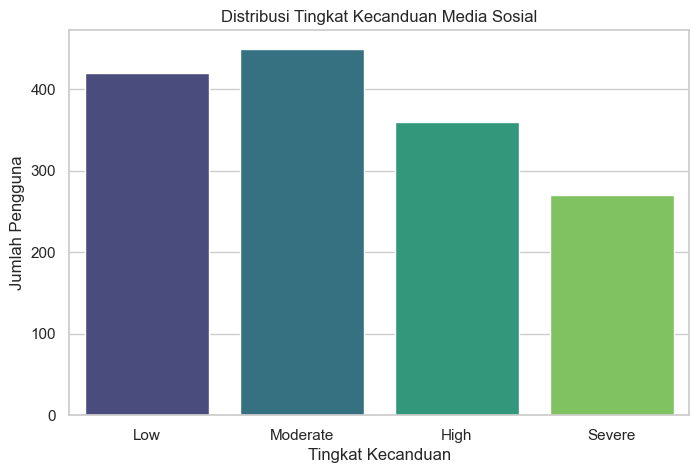

In [ ]:
# Visualisasi Distribusi Tingkat Kecanduan (Addiction_Level)
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Addiction_Level', palette='viridis', order=['Low', 'Moderate', 'High', 'Severe'] if 'Low' in df['Addiction_Level'].unique() else None)
plt.title('Distribusi Tingkat Kecanduan Media Sosial')
plt.xlabel('Tingkat Kecanduan')
plt.ylabel('Jumlah Pengguna')
plt.show()

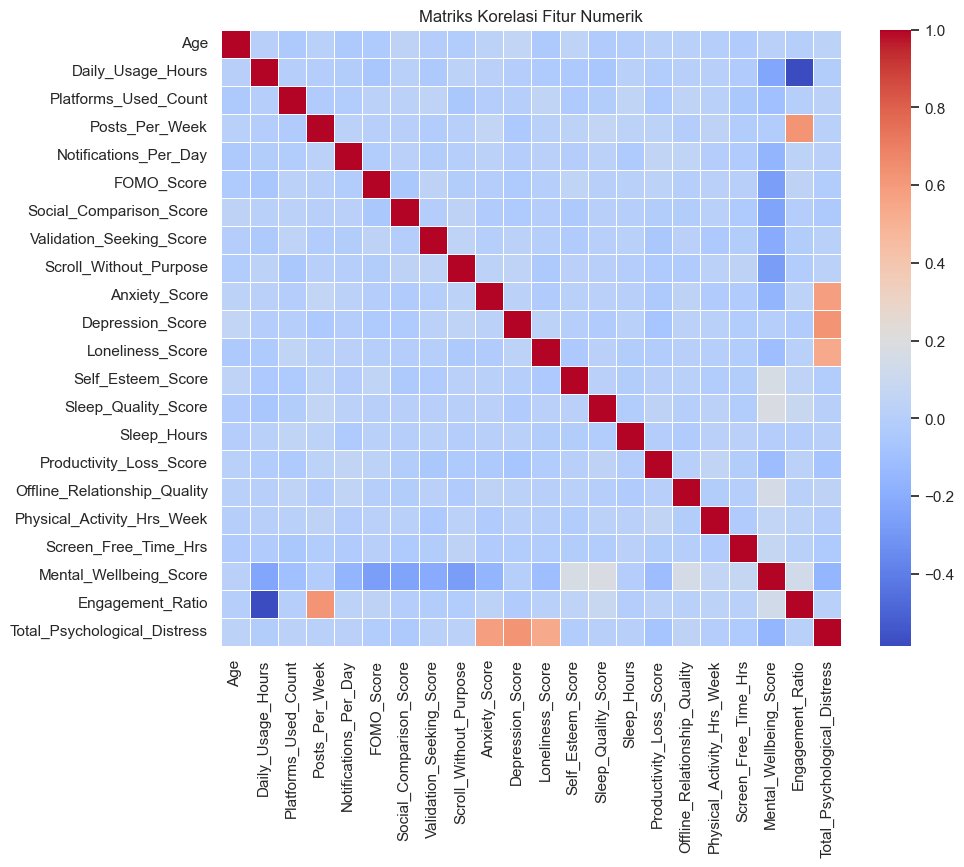

In [ ]:
# Visualisasi Korelasi Antar Fitur Numerik
plt.figure(figsize=(10, 8))
num_cols = df.select_dtypes(include=[np.number]).columns
corr = df[num_cols].corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', linewidths=0.5)
plt.title('Matriks Korelasi Fitur Numerik')
plt.show()

## 3. Machine Learning (Klasifikasi Addiction_Level)

In [ ]:
# Encoding Target
le = LabelEncoder()
y = le.fit_transform(df['Addiction_Level'])

# Memisahkan Fitur dan Target
X = df.drop(columns=['Addiction_Level'])

# One-Hot Encoding untuk variabel kategorikal
cat_cols = X.select_dtypes(include=['object']).columns
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)

# Scaling dengan StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_encoded)

# Penerapan PCA untuk reduksi dimensi
pca = PCA(n_components=10)
X_pca = pca.fit_transform(X_scaled)
print("Shape setelah PCA:", X_pca.shape)

Shape setelah PCA: (1500, 10)


In [ ]:
# Membagi data Training dan Testing
X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Pelatihan Model Random Forest
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train, y_train)

# Evaluasi Model
y_pred = clf.predict(X_test)
print("Akurasi Model:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=le.classes_))

Akurasi Model: 0.6466666666666666

Classification Report:
               precision    recall  f1-score   support

        High       0.55      0.47      0.50        77
         Low       0.79      0.80      0.80        80
    Moderate       0.49      0.59      0.54        79
      Severe       0.82      0.73      0.78        64

    accuracy                           0.65       300
   macro avg       0.66      0.65      0.65       300
weighted avg       0.66      0.65      0.65       300



Sumber Dataset: https://www.kaggle.com/datasets/harpartapsingh13/social-media-addiction-and-mental-wellbeing-dataset